In [18]:
from astropy.stats import sigma_clipped_stats
from astropy.visualization import SqrtStretch
from astropy.visualization.mpl_normalize import ImageNormalize
from astropy.wcs import WCS
from astropy.io import fits
import glob
import os
from scipy.stats import scoreatpercentile
import astropy.units as u
from scipy import stats

from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection
from matplotlib import pyplot as plt
import numpy as np
from matplotlib import colors

from pylab import *

from astropy.nddata import CCDData
#from ccdproc import ImageFileCollection, Combiner, combine
from ccdproc import wcs_project

#this is the code from part 3 so I can refrence it

ngc2291 = fits.getdata('cutout_102.7444_33.5250.fits')
hdul = fits.open("cutout_102.7444_33.5250.fits")
header = hdul[0].header
print(header)
naxis1= header["NAXIS1"]
naxis2= header["NAXIS2"]
naxis3= header["NAXIS3"]
band1=header["BAND1"]
band2=header["BAND2"]
band0=header["BAND0"]
print( '\nAxes are ', naxis1, ', ', naxis2, ', ', naxis3)
print('Bands are ', band0, ', ', band1, ', ', band2)
data = hdul[0].data
print(f"Data array shape: {data.shape}")
bunit = header.get(
 "BUNIT", "Not explicitly in header (Standard DECaLS: nanomaggies)"
)
print(f"Data units: {bunit}")
yc, xc = naxis2 // 2, naxis1 // 2
print(f"\nSample pixel values (Center of {band0}-band):")
print(data[0, yc - 1 : yc + 2, xc - 1 : xc + 2])
hdul.close()

Galaxies so I can refrence them

NGC 2291 - https://www.legacysurvey.org/viewer/cutout.jpg?ra=102.7443&dec=33.5250&layer=ls-dr11-north

NGC 5819 - https://www.legacysurvey.org/viewer/cutout.jpg?ra=223.5083&dec=73.1309&layer=ls-dr11-north

NGC 5888 - https://www.legacysurvey.org/viewer/cutout.jpg?ra=228.2794&dec=41.2652&layer=ls-dr11-north

NGC 5950 - https://www.legacysurvey.org/viewer/cutout.jpg?ra=232.8793&dec=40.4305&layer=ls-dr11-north

NGC 6449 - https://www.legacysurvey.org/viewer/cutout.jpg?ra=265.9447&dec=56.8043&layer=ls-dr11-north

NGC 6536 - https://www.legacysurvey.org/viewer/cutout.jpg?ra=269.3182&dec=64.9375&layer=ls-dr11-north

NGC 6651 - https://www.legacysurvey.org/viewer/cutout.jpg?ra=276.0840&dec=71.6033&layer=ls-dr11-north

IC 2222 - https://www.legacysurvey.org/viewer/cutout.jpg?ra=121.3114&dec=37.4724&layer=ls-dr11-north

IC 2424 - https://www.legacysurvey.org/viewer/cutout.jpg?ra=134.1994&dec=39.3815&layer=ls-dr11-north

IC 4010 - https://www.legacysurvey.org/viewer/cutout.jpg?ra=194.9757&dec=37.8591&layer=ls-dr11-north



In [19]:
#run the code from part 3 adapted to better naming. It gives me the header information and lets the variable names be the same from last time. 

ngc2291 = fits.getdata('Data/NGC2291.fits')
hdul = fits.open("Data/NGC2291.fits")
header = hdul[0].header
print(header)
naxis1= header["NAXIS1"]
naxis2= header["NAXIS2"]
naxis3= header["NAXIS3"]
band1=header["BAND1"]
band2=header["BAND2"]
band0=header["BAND0"]
print( '\nAxes are ', naxis1, ', ', naxis2, ', ', naxis3)
print('Bands are ', band0, ', ', band1, ', ', band2)
data = hdul[0].data
print(f"Data array shape: {data.shape}")
bunit = header.get(
 "BUNIT", "Not explicitly in header (Standard DECaLS: nanomaggies)"
)
print(f"Data units: {bunit}")
yc, xc = naxis2 // 2, naxis1 // 2
print(f"\nSample pixel values (Center of {band0}-band):")
print(data[0, yc - 1 : yc + 2, xc - 1 : xc + 2])
hdul.close()

SIMPLE  =                    T / file does conform to FITS standard             BITPIX  =                  -32 / number of bits per data pixel                  NAXIS   =                    3 / number of data axes                            NAXIS1  =                  256 / length of data axis 1                          NAXIS2  =                  256 / length of data axis 2                          NAXIS3  =                    3 / length of data axis 3                          EXTEND  =                    T / FITS dataset may contain extensions            COMMENT   FITS (Flexible Image Transport System) format is defined in 'AstronomyCOMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H SURVEY  = 'LegacySurvey'                                                        VERSION = 'DR11    '                                                            IMAGETYP= 'IMAGE   '           / None                                           BANDS   = 'grz     '                    

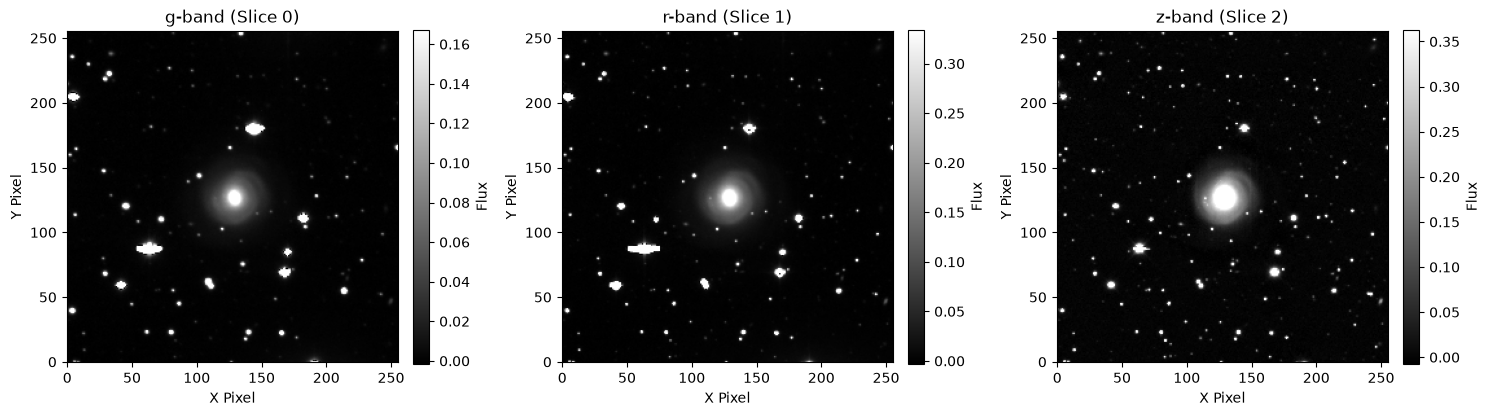

In [20]:

# data_cube[0] = g-band, data_cube[1] = r-band, data_cube[2] = z-band 
#plot the three bands to make sure things are loaded correctly and to give my brain more context

bands = ['g-band', 'r-band', 'z-band'] 

  

fig, axes = plt.subplots(1, 3, figsize=(15, 5)) 

  

for i, ax in enumerate(axes): 

  
    vmin, vmax = np.percentile(ngc2291[i], [1, 99]) 

     

    im = ax.imshow(ngc2291[i], origin='lower', cmap='gray', vmin=vmin, vmax=vmax) 

    ax.set_title(f'{bands[i]} (Slice {i})') 

    ax.set_xlabel('X Pixel') 

    ax.set_ylabel('Y Pixel') 

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Flux') 

  

plt.tight_layout() 

plt.show() 

In [21]:
#break the fits into bands


#steal the header from the orginial file
with fits.open("Data/NGC2291.fits") as hdul:
    NGC2291_header=hdul[0].header.copy()

#make a header for the bands 
for band_name, slice_idx, out_name in [
    ("g", 0, "NGC2291_g.fits"),
    ("r", 0, "NGC2291_r.fits"),
]:
    band_header=NGC2291_header.copy()
#get rid of the variables that we don't need
    for i in ("NAXIS3", "BANDS", "BAND0", "BAND1", "BAND2"):
        band_header.pop(i, None)
    band_header["BAND"]=(band_name, "Filter band")

    #split the data into their bands
    band_data=ngc2291[slice_idx]

    #make new fits file for each band
    hdu = fits.PrimaryHDU(data=band_data, header=band_header)
    hdu.writeto(out_name, overwrite=True)

In [46]:
#now I am going to steal a whole bunch of stuff from the surface photometry lab.
#it is already written and works and if I try to recreate it on my own it will take forever and probably won't run
#steal the imdisplay from surface photometry lab. Had vmin/max issues so added in stuff to get rid of them
def imdisplay(image, v1perc=10, v2perc=95, logscale=True):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    fig,ax = plt.subplots(figsize=(6,6))
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile



    #yay more vmin and vmax errors
    #make sure things are positive
    if logscale:
        pos_pixels = nimage[nimage > 0]
        if pos_pixels.size == 0:
          raise ValueError("Image has no positive pixels for LogNorm.")
        v1 = scoreatpercentile(nimage,v1perc)
        v2 = scoreatpercentile(nimage,v2perc)

        #make sure it actually does something
        if v1 <= 0:
          v1 = np.min(pos_pixels)
        if v2 <= v1:
          v2 = v1 * 10.0
        # display using imshow
        #
        # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
        # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
        #
        # vmin and vmax set the min and max pixel values that
        # will be mapped to the extremes of the colormap
        print(v1,v2)
        if (logscale):
            im = ax.imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
        else:
            im = ax.imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')
        
    cbar = fig.colorbar(im, ax=ax, fraction=0.04)
    cbar.ax.set_ylabel('counts')
    return fig,ax

2.0684037e-07 9.99975286960602


Text(0.5, 1.0, 'NGC2291_g.fits')

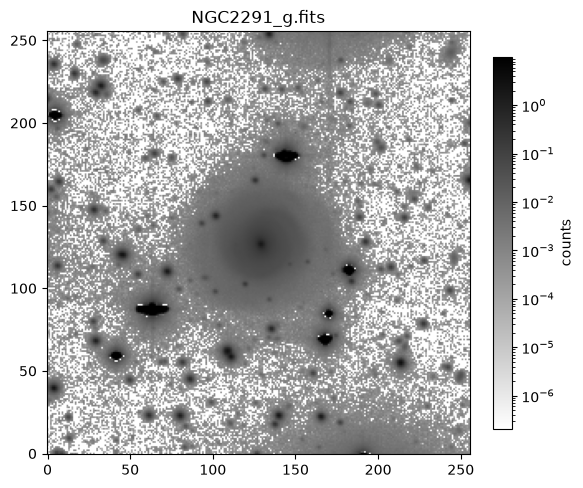

In [47]:
#steal this from problem 1 part 1 of surface photometry

imname = 'NGC2291_g.fits'
#fig,ax = plt.subplots(figsize=(6,6))
data,header = fits.getdata(imname, header=True)
fig,ax = imdisplay(data,v1perc=1,v2perc=99.9,logscale=True)

plt.title(imname)

In [57]:
#steal the background subtraction from surface photometry
#edit where the boxes are

def background_meas(imname,data,header,fig,ax,corners,bkg_size=5):
    #need to find ways to select regions of pixels in image
    fig,ax = imdisplay(data,v1perc=1,v2perc=99,logscale=True)

    plt.title(imname)

    #print out the x and y-dimension of the image using the header keywords
    print('image xdim = ', header['NAXIS1'], '; image ydim = ',header['NAXIS2'])
    #the length of each background box size
    #bkg_size = 200

    #make an array whose elements are the different data sections.
    reg = np.array([])


    #specify the different regions.  Each will be appended to the reg array.  the reg array is therefore 3 dimensional.  
    #the first dimension is for each region.  Each of those dimensions contains a 2D array that holds the image section.
    reg = np.append(reg, data[corners[0][0]:bkg_size-1, corners[0][1]:bkg_size-1])    #lower left corner
    reg = np.append(reg, data[corners[1][0]:bkg_size-1, corners[1][1]:])    #upper left corner
    reg = np.append(reg, data[corners[2][0]:, corners[2][1]:])    #upper right corner
    reg = np.append(reg, data[corners[3][0]:, corners[3][1]:bkg_size-1])   #lower right corner

    #print the median and mode of all the pixels. 
    bkgmode =stats.mode(reg,keepdims=False)[0]
    bkgmed = np.median(reg)
    print('mode = ',bkgmode)
    print('median = ',bkgmed)

    #Overlay rectangles with the background region indicated
    rectlist = []
    #loop through all images 
    for corn in corners:
        rect = plt.Rectangle((corn),bkg_size, bkg_size,linewidth=2,angle=0.0)
        rectlist.append(rect)
        pc = PatchCollection(rectlist,linewidth=1,edgecolor='r',facecolor='none')
        ax.add_collection(pc)
        
    return bkgmode,bkgmed
#initialize dictionaries that contains names of images and headers
imname = {}
data = {}
header = {}
corners = {}
bkgdim = {}

#statistics of background
bkgmode = {}
bkgmed = {}

#a routine to plot the images with the background measurement corners shown in red
def bkgregplot(data, header, imname, bkgdim, fig, ax, y_shift=30):
    x_max = header["NAXIS1"] - bkgdim
    y_max = header["NAXIS2"] - bkgdim
#the boxes contain some pieces of other galaxies so I am going to shift them so they don't 
    #make sure the boxes don't leave the image
    shift = min(y_shift, max(0, (y_max - bkgdim) // 2))
    #define lower-left corners of each region
    corners = [
        [0, 0],  # lower-left
        [0, y_max],  # upper-left
        [x_max, y_max - shift],  # upper-right moved LOWER
        [x_max, shift],  # lower-right moved HIGHER
  ]

    #run the background_meas code to measure the background and plot the background regions
    bkgmode,bkgmed = background_meas(imname, data, header, fig, ax, 
                                                       corners,bkg_size=bkgdim)
    return bkgmode, bkgmed

2.0684037e-07 0.16725708097219502
image xdim =  256 ; image ydim =  256
mode =  -0.0027565008495002985
median =  0.0003072335384786129


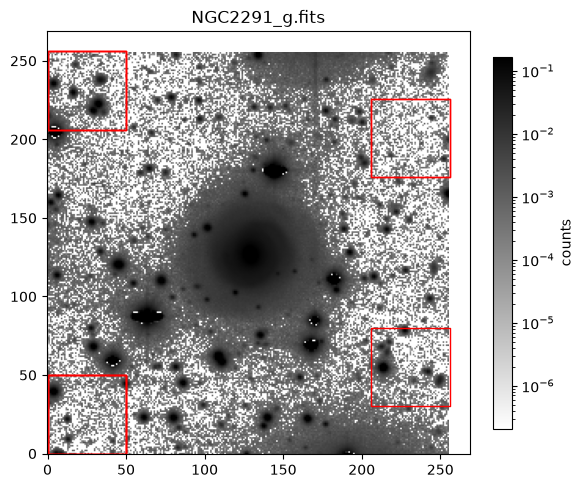

In [58]:
#steal this part from the surface photometry lab
galname = 'NGC2291_g'
imname[galname] = "NGC2291_g.fits"

#read fits image
data[galname],header[galname] = fits.getdata(imname[galname], header=True)

#the size of the background squares
bkgdim[galname]= 50

#plot image with background regions
bkgmode[galname],bkgmed[galname] = bkgregplot(
    data[galname], header[galname], imname[galname], bkgdim[galname], fig, ax)

In [63]:
#yay squares
#hopefully that is enough shift

#now for more theft
#initializse dictionary that will hold background subtracted images
data_bsub = {}
imname_bsub = {}

6.57164491713047e-08 9.999445636067541


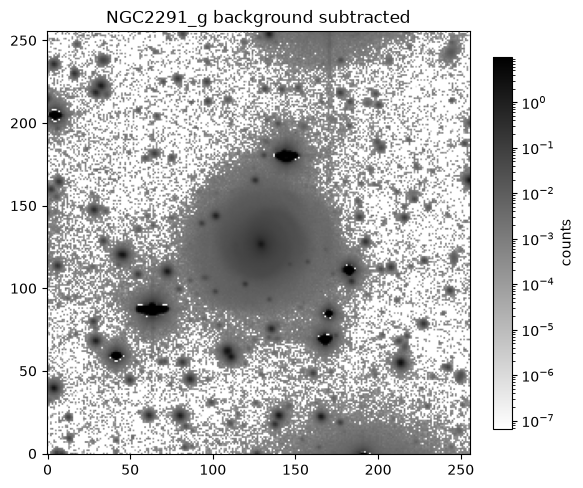

In [71]:
galname = 'NGC2291_g'

#background subtract the data
data_bsub[galname] = data[galname] - bkgmed[galname]
imname_bsub= {}
#display the background subtracted data
fig,ax =imdisplay(data_bsub[galname],v1perc=40,v2perc=99.9,logscale=True)

#add an image title
plt.title(galname + ' background subtracted')

#make a new image name that replaces one string with another
imname_bsub[galname] = imname[galname].replace(".fits","bsub.fits")

# save the background_subtracted image to a file
fits.writeto(imname_bsub[galname],data_bsub[galname],overwrite=True,header=header[galname])

In [74]:
#initialize the dictionary containing the intial parameters for the ellipse fitting
initparams = {}

In [75]:
#initiparams is a dictionary which contains an entry for each galaxy.  That dictionary in turns points to another dictionary with the parameters.
galname = 'NGC2291_g'
initparams[galname] = {}
#centroids [pixels]
initparams[galname]['xcen'] = 128
initparams[galname]['ycen'] = 126
#semi-major axis [pixels]
initparams[galname]['sma'] = 18
#semin-minor axis [pixels]
initparams[galname]['smina'] = 17
#ellipticity = 1-b/a
initparams[galname]['ellip'] = 1. - initparams[galname]['smina'] / initparams[galname]['sma'] 
#position angle, counterclockwise from the positive x-direction (right) [degrees]
initparams[galname]['PA'] = 0

In [76]:
from photutils.isophote import EllipseGeometry
from photutils.aperture import EllipticalAperture

#define an empty dictionary that will contain the EllipseGeometry instance
geometry = {}

18 0.05555555555555558
6.57164491713047e-08 10.105346775803513


Text(0.5, 1.0, 'NGC2291_g')

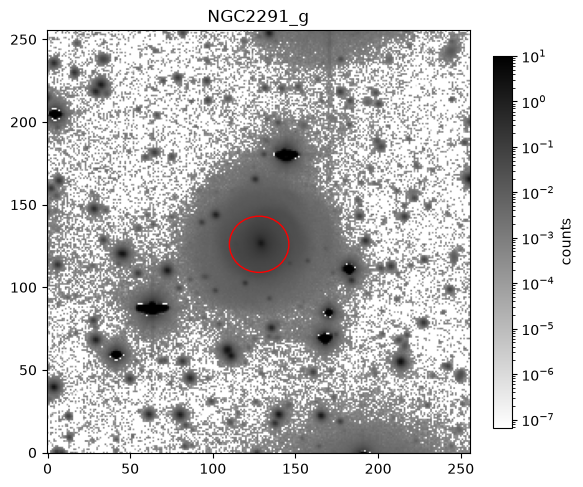

In [77]:
#set up the EllipseGeometry instance with the right initial guess parameters
galname = 'NGC2291_g'
geometry[galname] = EllipseGeometry(x0 = initparams[galname]['xcen'], 
                                      y0 = initparams[galname]['ycen'],
                                      sma = initparams[galname]['sma'],
                                      eps = initparams[galname]['ellip'],
                                      pa = initparams[galname]['PA'] * np.pi/180)   #convert into radians

print(geometry[galname].sma,geometry[galname].eps )
#make an aperture to overplot so that we can check if it makes sense
aper = EllipticalAperture((geometry[galname].x0, geometry[galname].y0), geometry[galname].sma, 
                          geometry[galname].sma * (1.-geometry[galname].eps), geometry[galname].pa)

#plot our image
#fig,ax = plt.subplots(figsize=(6,6))
fig,ax = imdisplay(data_bsub[galname],v1perc=40,v2perc=99.99,logscale=True)
aper.plot(color='red')
plt.title(galname)

In [78]:
def plotellipse(isolist):
    plt.figure(figsize=(8, 8))
    plt.subplots_adjust(hspace=0.35, wspace=0.35)

    #plot the semi-major axis vs. the ellipticity
    plt.subplot(2, 2, 1)
    plt.errorbar(isolist.sma, isolist.eps, yerr=isolist.ellip_err,
                 fmt='o', markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('Ellipticity')

    #plot the semi-major axis vs. the PA
    plt.subplot(2, 2, 2)
    plt.errorbar(isolist.sma, isolist.pa / np.pi * 180.0,
                 yerr=isolist.pa_err / np.pi * 80.0, fmt='o', markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('PA (deg)')

    #plot the semi-major axis vs. the x center of that ellipse
    plt.subplot(2, 2, 3)
    plt.errorbar(isolist.sma, isolist.x0, yerr=isolist.x0_err, fmt='o',
                 markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('x0')

    #plot the semi-major axis vs. the y center of that ellipse
    plt.subplot(2, 2, 4)
    plt.errorbar(isolist.sma, isolist.y0, yerr=isolist.y0_err, fmt='o',
                 markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('y0')

In [79]:
#this subroutine will plot every other isophote on top of the galaxy image
def plotaper(galname, image, isophote_list,vminperc=40,vmaxperc=99.99):

    #plot image
    #plt.subplots(figsize=(6,6))
    fig,ax = imdisplay2(image,v1perc=vminperc,v2perc=vmaxperc,logscale=True)

    #Loop through all apertures starting at the first (not zero) and going to every other aperture
    for i in range(1, len(isophote_list.sma),2):
        #create an elliptical aperture with the the correct geometry.  
        #Task is described here https://photutils.readthedocs.io/en/stable/api/photutils.aperture.EllipticalAperture.html#photutils.aperture.EllipticalAperture
        aperiter = EllipticalAperture((isophote_list.x0[i], isophote_list.y0[i]), isophote_list.sma[i], 
                                      isophote_list.sma[i] * (1-isophote_list.eps[i]), isophote_list.pa[i])
    
        #overplot apertures
        aperiter.plot(ax=ax[0],color='red')

    #plot the isophotes that have parameters fixed to the median parameters of all but the "apmin" inner isphotes
    #compute median isophote parameters ignoring inner isophotes.  This is because the inner isophotes all tend to be rather circular
    apmin = 20   #the minimum inner isophote in terms of isophote number.
    xcenav = np.median(isophote_list.x0[apmin:])
    ycenav = np.median(isophote_list.y0[apmin:])
    epsav = np.median(isophote_list.eps[apmin:])
    paav = np.median(isophote_list.pa[apmin:])
    
    #fig,ax = imdisplay(image,v1perc=vminperc,v2perc=vmaxperc,logscale=True)
    for i in range(1, len(isophote_list.sma),2):
        #create an elliptical aperture with the the correct geometry.  
        #Task is described here https://photutils.readthedocs.io/en/stable/api/photutils.aperture.EllipticalAperture.html#photutils.aperture.EllipticalAperture
        aperiter = EllipticalAperture((xcenav, ycenav), isophote_list.sma[i], 
                                      isophote_list.sma[i] * (1-epsav), paav)
    
        #overplot apertures
        aperiter.plot(ax=ax[1],color='blue')

    ax[0].set_title(galname + ' free ellipse parameters')
    ax[1].set_title(galname + ' fixed ellipse parameters')

    return xcenav, ycenav, epsav, paav

In [80]:
from photutils.isophote import Ellipse

#initialize dictionary for ellipse fitting
ellipse = {}
isolist = {}

In [81]:
xcenav = {}
ycenav = {}
epsav = {}
paav = {}

In [102]:
from photutils.aperture import ApertureStats
from photutils.aperture import EllipticalAnnulus, EllipticalAperture

#initialize dictionary for half-light radii
rhalfasec = {}

In [103]:

#this will do the fitting of the isophotes by making an instance of the Ellipse class
#It then fits the data using the initial guesses we computed above
galname = 'NGC2291_g'
ellipse[galname] = Ellipse(data_bsub[galname], geometry[galname])
isolist[galname] = ellipse[galname].fit_image()

In [104]:
def imdisplay2(image, v1perc=10, v2perc=95, logscale=True):
    '''
    display two copies of an image side-by-side
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    #this makes two horizontal figures 
    fig,axs = plt.subplots(1,2,figsize=(12,6))
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    if logscale:
        pos_pixels = nimage[nimage > 0]
        if pos_pixels.size == 0:
          raise ValueError("Image has no positive pixels for LogNorm.")
        v1 = scoreatpercentile(nimage,v1perc)
        v2 = scoreatpercentile(nimage,v2perc)

        #make sure it actually does something
        if v1 <= 0:
          v1 = np.min(pos_pixels)
        if v2 <= v1:
          v2 = v1 * 10.0
        # display using imshow
        #
        # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
        # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
        #
        # vmin and vmax set the min and max pixel values that
        # will be mapped to the extremes of the colormap
        print(v1,v2)
    if (logscale):
        #plot the two figures side by side
        im0 = axs[0].imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
        im1 = axs[1].imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
    else:
        im0 = axs[0].imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')
        im1 = axs[1].imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')

    #plot colorbars for each subplot
    cbar0 = fig.colorbar(im0, ax=axs[0], fraction=0.04)
    cbar0.ax.set_ylabel('counts')
    cbar1 = fig.colorbar(im1, ax=axs[1], fraction=0.04)
    cbar1.ax.set_ylabel('counts')
    return fig,axs

6.57164491713047e-08 10.105346775803513


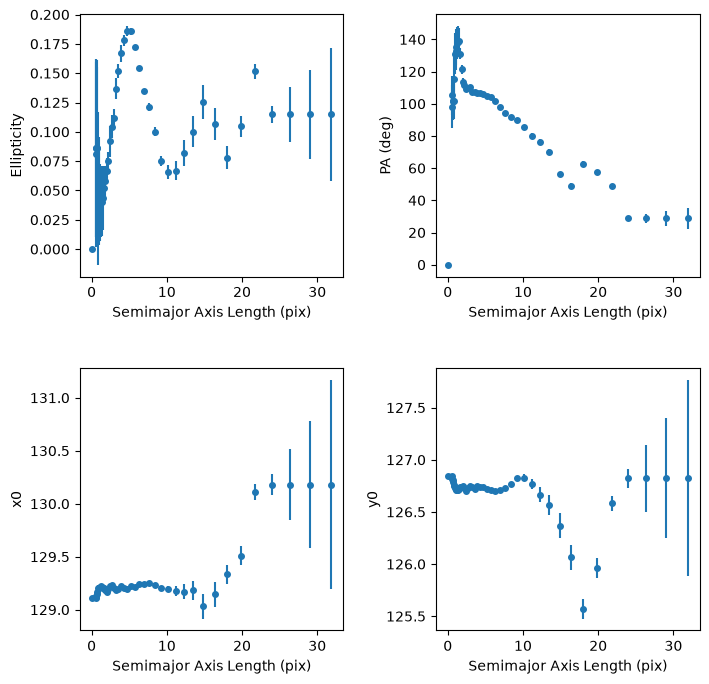

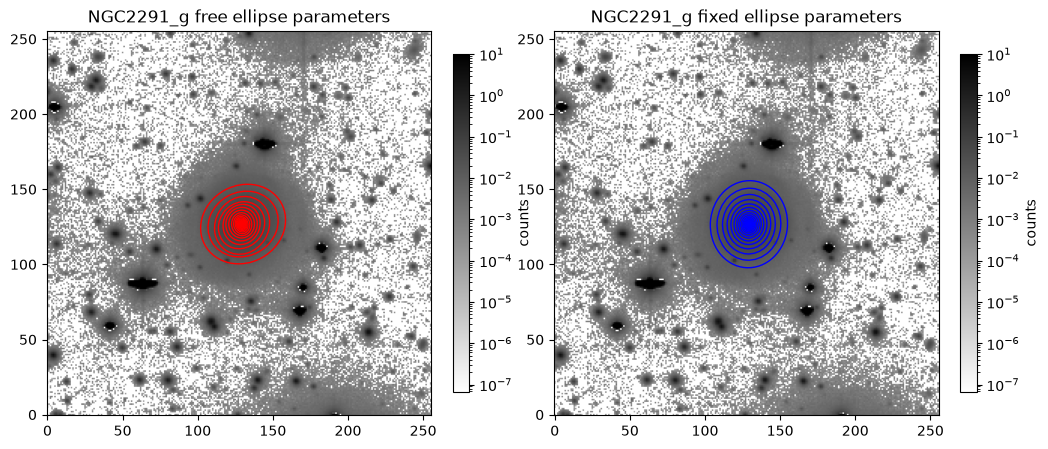

In [105]:
#this puts the output into a table containing every ellipse.   
#You can comment this first line out if you don't want it always to print out.
#print(isolist[galname].eps)

#make a set of plots that show some attributes of every ellipse.
plotellipse(isolist[galname])
#save the shape values of the average ellipse.  We will need this later for aperture photometry
xcenav[galname], ycenav[galname], epsav[galname], paav[galname] = plotaper(galname, data_bsub[galname],isolist[galname])

the half-light radius = 18.000 [asec]
SB within 3 asec (at r = 0.53 asec): 0.32 +/- 0.00 mag/asec^2
SB at r_half (r = 18.00 asec): 4.40 +/- 0.01 mag/asec^2
flux_SB(rhalf) / flux_SB(rcent) = 0.023


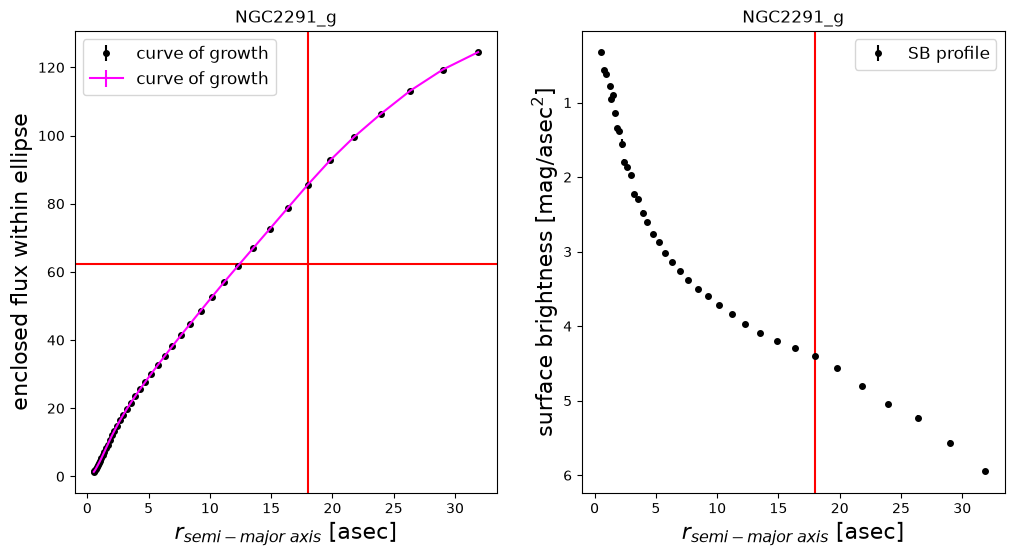

In [106]:
galname = 'NGC2291_g'

#we will use the isophote shape that corresponds to the average isophote values from the previous section
#xcenav[galname], ycenav[galname], epsav[galname], paav[galname]

#the magnitude zeropoint of the image, such that mag = -2.5 * log(flux) + magzp
magzp = header[galname][0]

#The pixel scale from the header converted from degrees to asec
pixscale = header[galname]['CD2_2'] * 3600.    #in asec/pix

#Go through every aperture and measure the surface brightness between it and the next most outer isophote
#initialize arrays for surface brightness and bin center
rcent = np.array([])
sbcent = np.array([])
sbcent_err = np.array([])
totflux = np.array([])
totflux_err = np.array([])
for aindx, a_out in enumerate(isolist[galname].sma):

    #skip the first isophote because I will always compute the values between the current isophote and the previous
    if aindx==0:
        a_in = 0.01

    if aindx>0:
        #create the inner and outer minor axes from the major axes and ellipticity
        b_out = a_out * (1.-epsav[galname])
        b_in = a_in * (1.-epsav[galname])

        #print(f'a_out = {a_out:.2f}; a_in ={a_in:.2f}; b_out ={b_out:.2f}; b_in ={b_in:.2f}')
        #set up elliptical annulus using parameters at rhalf
        annulus_aperture = EllipticalAnnulus((xcenav[galname],ycenav[galname]), 
                                             a_in, a_out, b_out, b_in = b_in,
                                             theta = paav[galname])
        total_aperture = EllipticalAperture((xcenav[galname],ycenav[galname]), 
                                             a_out, b_out, theta = paav[galname])
        aperstats_ann = ApertureStats(data_bsub[galname],annulus_aperture)
        aperstats_tot = ApertureStats(data_bsub[galname],total_aperture)
        a_in = a_out

        #the central radius of each annulus in asec.  I'm appending each central radius to the existing array
        rcent = np.append(rcent, (a_in + a_out) / 2.*pixscale)
        #the average pixel flux within each annulus
        avflux = aperstats_ann.mean
        #the standard deviation of the pixel values within each annulus
        stdflux = aperstats_ann.std
        #the number of pixels in each annulus
        numpix = aperstats_ann.sum_aper_area

        #Now do the total within each aperture
        totflux = np.append(totflux,aperstats_tot.sum)
        totflux_err = np.append(totflux_err,aperstats_tot.std)
        
        #****************************
        #your code here
        #the area of a pixel
        pixarea = pixscale*pixscale
        #determine the average surface brightness in mag/asec^2.
        sbcent = np.append(sbcent, -2.5 * np.log10(avflux / pixarea) + magzp)
        # the uncertainty in the mean flux (this is not the standard deviation of all the pixels in the aperture).  
        # Check back to Homework 1
        avflux_err = stdflux / np.sqrt(numpix)
        avflux_err = avflux_err * u.pix   #this gets rid of the units on the flux error so that the next part works
        sbcent_err = np.append(sbcent_err, (2.5 / np.log(10)) * (avflux_err / avflux))

fig,ax = plt.subplots(1,2,figsize=(12, 6))

#plot the semi-major axis vs. magnitude
ax[1].errorbar(rcent, sbcent, yerr=sbcent_err, 
             fmt='o', markersize=4, color='black', label='SB profile')
ax[1].invert_yaxis()

ax[1].legend(fontsize=12)

ax[1].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[1].set_ylabel('surface brightness [mag/asec$^2$]',fontsize=16)
ax[1].set_title(galname)

#plot the curve of growth
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='o', markersize=4, color='black', label='curve of growth')
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='-', markersize=4, color='magenta', label='curve of growth')

#ax[0].axvline(rhalfasec[galname], color='red', label='$r_{half}$')
ax[0].legend(fontsize=12)

ax[0].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[0].set_ylabel('enclosed flux within ellipse',fontsize=16)
ax[0].set_title(galname)

#measure the half-light radius
#a horizontal line at half the total flux
ax[0].axhline(totflux[-1]/2., color='red')

#a vertical line at half the total flux
#*************************
#You will need to adjust rhalfpix by eye to get the radius that encompasses half the light.
#you shoul do this using the plot you make, not using the image itself.
rhalfasec[galname] = 18
ax[0].axvline(rhalfasec[galname], color='red')
print(f'the half-light radius = {rhalfasec[galname]:.3f} [asec]')

#plot the same line on the surface brightness plot
ax[1].axvline(rhalfasec[galname], color='red', label='$r_{half}$')

#calculate and print the surface brightness somewhere within 3 arcsec from the center.  
#Note that some of the inner values have NaNs because the isophote fitting failed there.  
#Just keep going out in index until you get a valid value
#***********************
valid_inner = np.where((rcent <= 3.0) & (~np.isnan(sbcent)))[0]
inner_idx = valid_inner[0]
print(f"SB within 3 asec (at r = {rcent[inner_idx]:.2f} asec): {sbcent[inner_idx]:.2f} +/- {sbcent_err[inner_idx]:.2f} mag/asec^2")

#calculate and print out the surface brightness at the effective radius
#***********************
#your code here
#find the isophote that best corresponds to the half-light radius
#We will do this by computing the difference between the half-light radius
#and the semi-major axis of each isophote.  
diff = rcent - rhalfasec[galname]

#this returns the index of the isophote that is closes to the half-light radius
#We use this to set the ellipticity and PA of the isophotes
rhalfasecind = np.argmin(abs(diff))

diff = rcent - rhalfasec[galname]
rhalfasecind = np.argmin(abs(diff))
print(f"SB at r_half (r = {rcent[rhalfasecind]:.2f} asec): {sbcent[rhalfasecind]:.2f} +/- {sbcent_err[rhalfasecind]:.2f} mag/asec^2")

#calculate and print out the ratio of the **flux** surface brightness between the center and at r_half
#***********************
#your code here
sb_center = sbcent[inner_idx]
sb_rhalf = sbcent[rhalfasecind]
flux_rat = 10**(-0.4 * (sb_rhalf - sb_center))
print(f'flux_SB(rhalf) / flux_SB(rcent) = {flux_rat:.3f}')